# Segmentación por Valor y Frecuencia (modelo de 2 ejes + estado)

Implementa el modelo propuesto: dos capas de naturaleza distinta que comparten la misma base, para que una sola segmentación sirva tanto para medir LTV como para accionar en CRM.

- **Capa estructural (estable):** cada cliente tiene un **Valor** (margen de contribución acumulado de toda su vida) y una **Frecuencia** (compras por año de vida). El número de niveles de cada eje no se fija a mano: lo determina el **método del codo** sobre esa variable. Los ejes se cruzan (ej. 3 metales × 3 niveles de frecuencia = 9 grupos estructurales).
- **Capa de estado (dinámica):** cada grupo estructural tiene su propio **umbral de muerte** (percentil 90 de los intervalos entre compras de sus clientes). El estado de un cliente (Activo / Por inactivar / Inactivo) se calcula comparando su recencia contra el umbral de *su propio grupo*, no contra una ventana fija de 12 meses igual para todos.

In [218]:
import time
import pandas as pd
import numpy as np
from datetime import date
import pathlib
from sqlalchemy import create_engine
import urllib
import os
from dotenv import load_dotenv
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

load_dotenv()
sns.set_theme(style="whitegrid")

In [219]:
params = urllib.parse.quote_plus(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={os.getenv('DB_SERVER')};"
    "DATABASE=Ventas_Comerssia;"
    f"UID={os.getenv('DB_USER')};"
    f"PWD={os.getenv('DB_PASSWORD')};"
)

engine = create_engine(
    f"mssql+pyodbc:///?odbc_connect={params}",
    pool_pre_ping=True,
    pool_recycle=180,
)


def leer_con_reintentos(query, engine, intentos=4, espera=10):
    """Reintenta la consulta con una conexión nueva cada vez (protege contra
    cortes de red/VPN, sobre todo después de un cómputo largo en Python)."""
    for intento in range(1, intentos + 1):
        try:
            return pd.read_sql(query, engine)
        except Exception as e:
            engine.dispose()
            if intento == intentos:
                raise
            print(f"Intento {intento}/{intentos} falló ({type(e).__name__}); reintentando en {espera}s...")
            time.sleep(espera)

In [ ]:
fecha_corte = pd.to_datetime("2026-08-31")
FECHA_CORTE_INICIO = date(2024, 1, 1)  # <-- cambiar aquí para cada corrida

PERCENTIL_UMBRAL = 90        # percentil de los intervalos entre compras que define "muerte" del grupo
CORTE_ACTIVO = 0.7           # Activo si recencia < CORTE_ACTIVO * umbral_grupo
K_RANGE = range(2, 7)        # niveles a probar con el método del codo (2 a 6), por eje
MIN_INTERVALOS_CONFIABLE = 30  # bajo este número de intervalos, el umbral del grupo se considera poco confiable
AÑOS_VIDA_MINIMO = 30 / 365.25  # piso de 1 mes para años de vida (evita Frecuencia -> infinito en clientes nuevos)

SEPARAR_UNICO = True  # <-- cambiar a False para el otro escenario (ver sección "Categoría Único")

METALES = ["Diamante", "Oro", "Plata", "Bronce", "Cobre"]
NIVELES_FRECUENCIA = ["Alta", "Media", "Baja", "Muy Baja", "Mínima"]

# Carpeta de salida propia para esta corrida -- así cada combinación de ventana de
# historia (FECHA_CORTE_INICIO) y escenario (SEPARAR_UNICO) deja sus gráficos y Excel
# en su propia carpeta, sin pisar los de otra corrida.
OUTPUT_DIR = pathlib.Path(
    f"resultados_{FECHA_CORTE_INICIO.year}_{'con_unico' if SEPARAR_UNICO else 'sin_unico'}"
)
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Carpeta de salida de esta corrida: {OUTPUT_DIR}/")

Carpeta de salida de esta corrida: resultados_2024_sin_unico/


## 1. Extracción de datos (historial completo, no una ventana)

El LTV necesita la vida completa del cliente, no una ventana de 12 o 24 meses — por eso aquí se trae **todo** el historial de `Ventas_Unificadas` (la llave única cubre cohortes desde 2019). Es una consulta más pesada que la del notebook de K-Means.

In [221]:
# Se trae por año, directo de SQL siempre (sin caché en disco) -- la consulta es rápida
# y así cada corrida con una FECHA_CORTE_INICIO distinta queda completamente autocontenida.
COLUMNAS = ["ID_Cliente_Unico", "Pedido", "Fecha", "Cantidad", "Venta_Neta", "Costo_Promedio", "Forma_Pago"]

# Cuentas genéricas / de canal / de prueba que NO son clientes reales -- se excluyen por
# Cliente (no por ID_Cliente_Unico) porque un mismo ID_Cliente_Unico puede traer mezclado
# un cliente real con uno genérico (ej. ID 206829 mezclaba a Catalina Gómez Barrera con
# "Consumidor Final"). Revisar/actualizar esta lista periódicamente.
CLIENTES_EXCLUIR = [
    "C222222222222", "C22222222222", "CN","C1",
    "C111", "C1111111111","C77", "C777","C000000000",
    "C12235456", "C123456","C1234567","C900790149",
]
clientes_excluir_sql = ", ".join(f"'{c}'" for c in CLIENTES_EXCLUIR)

# SKU con Costo_Promedio corrupto (filas duplicadas con costo unitario absurdo) -- excluir
# hasta que se corrija en el origen.
SKUS_EXCLUIR = ["2069"]
skus_excluir_sql = ", ".join(f"'{s}'" for s in SKUS_EXCLUIR)

# Canales cuyo Costo_Promedio no es confiable todavía -- excluir mientras se corrige.
CANALES_EXCLUIR = ["Shopify", "CHATCENTER WEB"]
canales_excluir_sql = ", ".join(f"'{c}'" for c in CANALES_EXCLUIR)

partes = []
for año in range(FECHA_CORTE_INICIO.year, fecha_corte.year + 1):
    query_año = f"""
    SELECT {', '.join(COLUMNAS)}
    FROM Ventas_Comerssia.dbo.Ventas_Unificadas
    WHERE ID_Cliente_Unico IS NOT NULL
      AND YEAR(Fecha) = {año}
      AND Fecha >= '{FECHA_CORTE_INICIO:%Y-%m-%d}'
      AND Fecha <= '{fecha_corte:%Y-%m-%d}'
      AND Cliente NOT IN ({clientes_excluir_sql})
      AND Sku NOT IN ({skus_excluir_sql})
      AND Canal NOT IN ({canales_excluir_sql})
    """
    parte = leer_con_reintentos(query_año, engine)
    print(f"  {año}: {len(parte):,} filas (descargadas)")
    partes.append(parte)

df_ventas = pd.concat(partes, ignore_index=True)
df_ventas["Fecha"] = pd.to_datetime(df_ventas["Fecha"], errors="coerce")
print(f"Filas: {len(df_ventas):,} | Clientes únicos: {df_ventas['ID_Cliente_Unico'].nunique():,}")

  2024: 341,192 filas (descargadas)
  2025: 319,834 filas (descargadas)
  2026: 161,175 filas (descargadas)
Filas: 822,201 | Clientes únicos: 141,555


## 2. Margen de contribución por transacción

`Ventas_Unificadas` no trae una columna de margen ya calculada, así que se arma con lo que sí existe:

**Margen = Venta_Neta − (Costo_Promedio × Cantidad)**

- `Venta_Neta` ya viene sin IVA (se verificó contra `Venta`: `Venta_Neta ≈ Venta / 1.19`), y las devoluciones ya están como filas con `Cantidad` negativa (no hay tabla aparte de devoluciones) — al sumar, se restan solas.
- `Costo_Promedio` es el costo unitario, por eso se multiplica por `Cantidad` para obtener el costo de la línea.

In [222]:
df_ventas["Margen"] = df_ventas["Venta_Neta"] - (df_ventas["Costo_Promedio"].fillna(0) * df_ventas["Cantidad"])

In [223]:
# --- Cambio 1: las devoluciones (NOTA CREDITO) generan su propio Pedido, así que hoy
# se cuentan como una "visita" adicional -- inflando Frecuencia y acortando artificialmente
# los intervalos entre compras. Se marcan aquí para separarlas de la actividad real.
df_ventas["EsDevolucion"] = df_ventas["Forma_Pago"] == "NOTA CREDITO"

n_filas_devolucion = int(df_ventas["EsDevolucion"].sum())
n_clientes_devolucion = df_ventas.loc[df_ventas["EsDevolucion"], "ID_Cliente_Unico"].nunique()
print(f"Filas marcadas como devolución (Forma_Pago = NOTA CREDITO): {n_filas_devolucion:,}")
print(f"Clientes distintos con al menos una devolución: {n_clientes_devolucion:,}")

# df_ventas (todas las filas) se sigue usando para el Valor -- una devolución sí debe
# restar del margen total del cliente, eso no cambia. df_visitas (sin devoluciones) es
# la vista que mide actividad de compra real: cosecha, última compra, frecuencia e
# intervalos entre compras.
df_visitas = df_ventas[~df_ventas["EsDevolucion"]].copy()
print(f"df_visitas (sin devoluciones): {len(df_visitas):,} filas")

Filas marcadas como devolución (Forma_Pago = NOTA CREDITO): 6,527
Clientes distintos con al menos una devolución: 3,587
df_visitas (sin devoluciones): 815,674 filas


## 3. Variables por cliente: Valor, Frecuencia, cosecha y recencia

In [224]:
clientes_actividad = (
    df_visitas.groupby("ID_Cliente_Unico")
    .agg(
        CosechaFecha=("Fecha", "min"),
        UltimaCompra=("Fecha", "max"),
        n_compras=("Pedido", "nunique"),
    )
    .reset_index()
)
clientes_valor = df_ventas.groupby("ID_Cliente_Unico")["Margen"].sum().reset_index(name="Valor")

# DECISIÓN EXPLÍCITA: un cliente cuya ÚNICA transacción es una devolución (Cantidad
# negativa, Forma_Pago = NOTA CREDITO) no tiene ninguna visita real -- no puede tener
# CosechaFecha, Frecuencia ni Estado con sentido. Se EXCLUYE del modelo (no se le deja
# como NaN ni se le asigna una categoría propia). Su margen (siempre negativo) también
# sale de la base, así que se reporta aquí para que la reconciliación de Valor total
# quede explicada, no perdida en silencio.
ids_solo_devolucion = set(clientes_valor["ID_Cliente_Unico"]) - set(clientes_actividad["ID_Cliente_Unico"])
margen_excluido = clientes_valor.set_index("ID_Cliente_Unico").loc[list(ids_solo_devolucion), "Valor"].sum() if ids_solo_devolucion else 0.0
print(f"Clientes excluidos del modelo por no tener ninguna visita real (solo devolución): {len(ids_solo_devolucion):,}")
print(f"Margen de esos clientes, excluido de 'clientes' (queda fuera de Valor por cliente, no del margen real del negocio): {margen_excluido:,.0f}")

clientes = clientes_actividad.merge(clientes_valor, on="ID_Cliente_Unico", how="left")

años_vida = (fecha_corte - clientes["CosechaFecha"]).dt.days / 365.25
clientes["AñosVida"] = años_vida.clip(lower=AÑOS_VIDA_MINIMO)
clientes["Frecuencia"] = clientes["n_compras"] / clientes["AñosVida"]
clientes["RecenciaMeses"] = (fecha_corte - clientes["UltimaCompra"]).dt.days / 30.44

clientes = clientes[clientes["n_compras"] > 0].reset_index(drop=True)

# Reconciliación: el Valor total sobre clientes debe diferir del margen total de
# df_ventas exactamente en el margen de los clientes excluidos arriba -- si no cuadra,
# algo más además de "solo devolución" está perdiendo clientes silenciosamente.
diferencia_valor = df_ventas["Margen"].sum() - clientes["Valor"].sum()
assert abs(diferencia_valor - margen_excluido) < 1, (
    f"Reconciliación de Valor no cuadra: diferencia={diferencia_valor:,.0f} vs margen_excluido={margen_excluido:,.0f}"
)

print(f"Clientes con al menos una compra (sin contar devoluciones como visita): {len(clientes):,}")
clientes[["Valor", "Frecuencia", "RecenciaMeses"]].describe()

Clientes excluidos del modelo por no tener ninguna visita real (solo devolución): 2
Margen de esos clientes, excluido de 'clientes' (queda fuera de Valor por cliente, no del margen real del negocio): -1,008,826
Clientes con al menos una compra (sin contar devoluciones como visita): 141,553


,Valor,Frecuencia,RecenciaMeses
count,1.415530e+05,141553.000000,141553.000000
mean,3.743667e+05,1.862302,13.280434
std,7.449298e+05,2.278274,8.942978
min,-8.326902e+05,0.375772,0.000000
25%,7.829661e+04,0.611809,5.814717
50%,1.708350e+05,1.182039,11.333771
75%,3.767866e+05,2.063559,20.466491
max,5.620952e+07,97.400000,31.931669


In [225]:
# --- Excluir del modelo a los clientes con Valor (margen de vida) negativo ---
# Ya investigados: 51 por devolución genuina, 74 por productos promocionales/liquidaciones
# (125 casos, ~0.05% de la base). No pasan por Metal/Frecuencia/Estado ni por el codo/K-means
# -- se guardan aparte solo para trazabilidad (hoja "Excluidos_Margen_Negativo" del Excel).
clientes_excluidos_margen_negativo = clientes.loc[clientes["Valor"] < 0, ["ID_Cliente_Unico", "Valor"]].copy()
clientes = clientes[clientes["Valor"] >= 0].reset_index(drop=True)

n_excluidos_margen_negativo = len(clientes_excluidos_margen_negativo)
print(f"Clientes excluidos del modelo por Valor negativo: {n_excluidos_margen_negativo:,} "
      f"({n_excluidos_margen_negativo / (len(clientes) + n_excluidos_margen_negativo) * 100:.3f}% de la base)")

Clientes excluidos del modelo por Valor negativo: 44 (0.031% de la base)


### Categoría "Único": clientes con exactamente 1 compra

Con `SEPARAR_UNICO = True`, un cliente con una sola compra en toda su historia no
tiene un segundo intervalo que medir, así que su Frecuencia anualizada no significa
lo mismo que la de un recomprador -- se separa en su propio nivel
`NivelFrecuencia = "Único"`, sin importar su antigüedad, y no entra al codo/K-means
de Frecuencia. Su Metal sí se calcula igual que para el resto de la población (el
codo de Valor no cambia por este parámetro).

Con `SEPARAR_UNICO = False`, estos clientes entran al codo/K-means de Frecuencia
como cualquier otro (versión más simple: Metal x Frecuencia con 3 niveles, sin
categoría "Único").

In [226]:
# --- Marcar clientes con exactamente 1 compra (categoría "Único", ver SEPARAR_UNICO) ---
clientes["EsUnico"] = clientes["n_compras"] == 1
print(f"Clientes con exactamente 1 compra: {clientes['EsUnico'].sum():,} ({clientes['EsUnico'].mean()*100:.1f}%)")

Clientes con exactamente 1 compra: 83,932 (59.3%)


## 4. Eje de Valor — método del codo


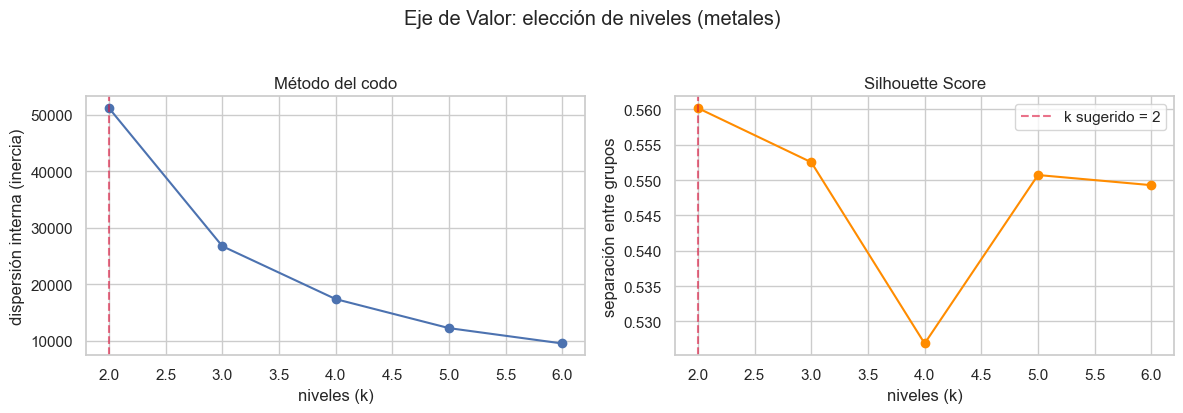

k=2: silhouette=0.560  <-- sugerido
k=3: silhouette=0.553
k=4: silhouette=0.527
k=5: silhouette=0.551
k=6: silhouette=0.549


In [227]:
def elegir_niveles(valores, k_range=K_RANGE, n_init=8):
    """Aplica el método del codo (+ silhouette) a una variable 1D.
    Devuelve (inercias, silhouettes, k_sugerido, transformador, X)"""
    x_t = np.arcsinh(valores.to_numpy()).reshape(-1, 1)
    scaler = StandardScaler()
    X = scaler.fit_transform(x_t)

    inertias, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=n_init)
        labels = km.fit_predict(X)
        inertias.append(km.inertia_)
        # sample_size: silhouette con TODOS los clientes es O(n^2) -- con ~270k clientes
        # eso son decenas de miles de millones de comparaciones por cada k (~90 min).
        # Una muestra de 10,000 es estadísticamente representativa y baja esto a segundos.
        silhouettes.append(silhouette_score(X, labels, sample_size=10000, random_state=42))

    k_sugerido = list(k_range)[int(np.argmax(silhouettes))]
    return inertias, silhouettes, k_sugerido, scaler, X


def graficar_codo(k_range, inertias, silhouettes, k_sugerido, titulo, archivo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(list(k_range), inertias, marker="o")
    axes[0].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6)
    axes[0].set_title("Método del codo")
    axes[0].set_xlabel("niveles (k)")
    axes[0].set_ylabel("dispersión interna (inercia)")

    axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
    axes[1].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6, label=f"k sugerido = {k_sugerido}")
    axes[1].set_title("Silhouette Score")
    axes[1].set_xlabel("niveles (k)")
    axes[1].set_ylabel("separación entre grupos")
    axes[1].legend()

    fig.suptitle(titulo, y=1.03)
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


inertias_v, silhouettes_v, k_valor, scaler_valor, X_valor = elegir_niveles(clientes["Valor"])
graficar_codo(
    K_RANGE, inertias_v, silhouettes_v, k_valor,
    "Eje de Valor: elección de niveles (metales)",
    OUTPUT_DIR / "grafico_1_codo_valor_v2.png",
)
for k, s in zip(K_RANGE, silhouettes_v):
    marca = "  <-- sugerido" if k == k_valor else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

## 5. Eje de Frecuencia — método del codo

**Gráfico 2.** Mismo procedimiento sobre la Frecuencia (compras por año de vida).

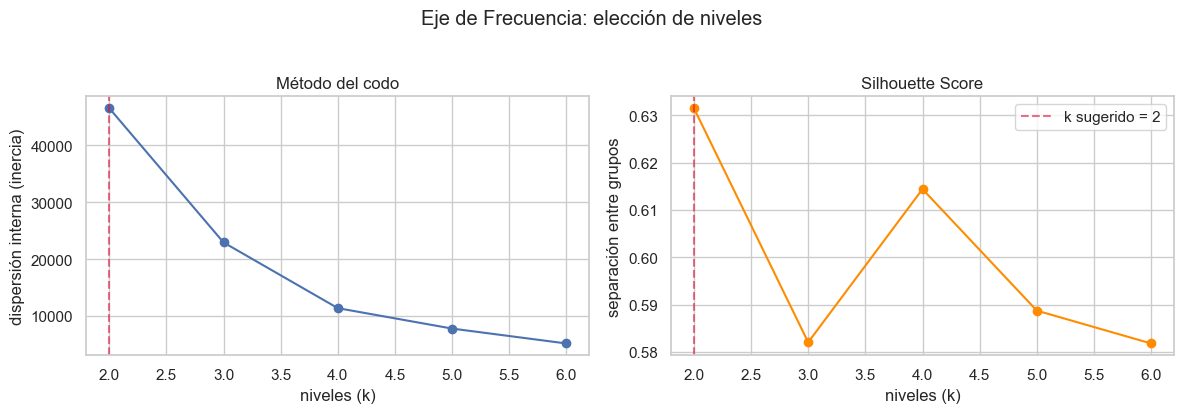

k=2: silhouette=0.631  <-- sugerido
k=3: silhouette=0.582
k=4: silhouette=0.614
k=5: silhouette=0.589
k=6: silhouette=0.582


In [228]:
mask_frecuencia_entrenamiento = ~clientes["EsUnico"] if SEPARAR_UNICO else pd.Series(True, index=clientes.index)

inertias_f, silhouettes_f, k_frecuencia, scaler_frec, X_frec = elegir_niveles(clientes.loc[mask_frecuencia_entrenamiento, "Frecuencia"])
graficar_codo(
    K_RANGE, inertias_f, silhouettes_f, k_frecuencia,
    "Eje de Frecuencia: elección de niveles",
    OUTPUT_DIR / "grafico_2_codo_frecuencia_v2.png",
)
for k, s in zip(K_RANGE, silhouettes_f):
    marca = "  <-- sugerido" if k == k_frecuencia else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

## 6. Niveles finales y etiquetas

Si el negocio requiere otro número de niveles en algún eje (por ejemplo, para calzar con la nomenclatura de metales ya conocida), sobrescribir `K_VALOR` / `K_FRECUENCIA` aquí.

In [229]:
K_VALOR = 3            # <-- sobrescribe con un entero si el negocio prefiere otro número de metales
K_FRECUENCIA = 3        # <-- sobrescribe con un entero si el negocio prefiere otro número de niveles (sin contar "Único")

mask_frecuencia_entrenamiento = ~clientes["EsUnico"] if SEPARAR_UNICO else pd.Series(True, index=clientes.index)

# El Metal (eje de Valor) se calcula con TODA la población, sin excepción.
km_valor = KMeans(n_clusters=K_VALOR, random_state=42, n_init=8)
clientes["Cluster_Valor"] = km_valor.fit_predict(X_valor)

# El NivelFrecuencia se entrena solo con quienes SÍ participan del codo de Frecuencia
# (ver mask_frecuencia_entrenamiento arriba) -- los "Único" (si SEPARAR_UNICO=True) no.
km_frec = KMeans(n_clusters=K_FRECUENCIA, random_state=42, n_init=8)
clientes.loc[mask_frecuencia_entrenamiento, "Cluster_Frecuencia"] = km_frec.fit_predict(X_frec)

orden_valor = clientes.groupby("Cluster_Valor")["Valor"].mean().sort_values(ascending=False).index.tolist()
mapa_metal = {c: METALES[i] if i < len(METALES) else f"Nivel Valor {i+1}" for i, c in enumerate(orden_valor)}

orden_frec = clientes.loc[mask_frecuencia_entrenamiento].groupby("Cluster_Frecuencia")["Frecuencia"].mean().sort_values(ascending=False).index.tolist()
mapa_frecuencia = {c: NIVELES_FRECUENCIA[i] if i < len(NIVELES_FRECUENCIA) else f"Nivel Frec {i+1}" for i, c in enumerate(orden_frec)}

clientes["Metal"] = clientes["Cluster_Valor"].map(mapa_metal)
clientes["NivelFrecuencia"] = clientes["Cluster_Frecuencia"].map(mapa_frecuencia)

if SEPARAR_UNICO:
    clientes.loc[clientes["EsUnico"], "NivelFrecuencia"] = "Único"

clientes["GrupoEstructural"] = clientes["Metal"] + " / " + clientes["NivelFrecuencia"]

orden_metales = [mapa_metal[c] for c in orden_valor]
orden_niveles_frec = [mapa_frecuencia[c] for c in orden_frec] + (["Único"] if SEPARAR_UNICO else [])

n_grupos_posibles = len(orden_metales) * len(orden_niveles_frec)
print(f"Metales (Valor): {orden_metales}")
print(f"Niveles (Frecuencia): {orden_niveles_frec}")
print(f"Grupos estructurales: {len(orden_metales)} x {len(orden_niveles_frec)} = {n_grupos_posibles} posibles")
clientes["GrupoEstructural"].value_counts()

Metales (Valor): ['Diamante', 'Oro', 'Plata']
Niveles (Frecuencia): ['Alta', 'Media', 'Baja']
Grupos estructurales: 3 x 3 = 9 posibles


GrupoEstructural
Plata / Baja        34033
Oro / Baja          33720
Oro / Media         23065
Diamante / Media    17237
Plata / Media       12631
Diamante / Alta      6329
Diamante / Baja      5529
Oro / Alta           5366
Plata / Alta         3599
Name: count, dtype: int64

In [230]:
# --- Impacto de excluir las devoluciones del conteo de Frecuencia ---
# Compara, para los mismos clientes (los que entrenaron el eje de Frecuencia) y el
# mismo modelo ya ajustado, el NivelFrecuencia que habrían tenido si las devoluciones
# SÍ contaran como visita.
n_compras_con_devolucion = df_ventas.groupby("ID_Cliente_Unico")["Pedido"].nunique()
frecuencia_vieja = (
    n_compras_con_devolucion / clientes.set_index("ID_Cliente_Unico")["AñosVida"]
).reindex(clientes["ID_Cliente_Unico"])

mask_frecuencia_entrenamiento = ~clientes["EsUnico"] if SEPARAR_UNICO else pd.Series(True, index=clientes.index)
idx_entrenamiento = clientes.index[mask_frecuencia_entrenamiento]
frecuencia_vieja_entrenamiento = frecuencia_vieja.loc[clientes.loc[idx_entrenamiento, "ID_Cliente_Unico"]].to_numpy()
X_frec_vieja = scaler_frec.transform(np.arcsinh(frecuencia_vieja_entrenamiento).reshape(-1, 1))
nivel_frec_vieja = pd.Series(km_frec.predict(X_frec_vieja), index=idx_entrenamiento).map(mapa_frecuencia)

cambios_frecuencia = int((nivel_frec_vieja != clientes.loc[idx_entrenamiento, "NivelFrecuencia"]).sum())
print("Impacto de NO contar las devoluciones como visita:")
print(f"  Clientes que habrían quedado en otro NivelFrecuencia: {cambios_frecuencia:,} "
      f"({cambios_frecuencia / len(idx_entrenamiento) * 100:.1f}% de los clientes que entrenaron el eje de Frecuencia)")

Impacto de NO contar las devoluciones como visita:
  Clientes que habrían quedado en otro NivelFrecuencia: 955 (0.7% de los clientes que entrenaron el eje de Frecuencia)


In [231]:
# Rango de Valor y Frecuencia por nivel -- listo para copiar a un documento

def fmt_cop(valor):
    return "$" + f"{valor:,.0f}".replace(",", ".")


tabla_valor = (
    clientes.groupby("Metal")["Valor"]
    .agg(["min", "max", "mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
tabla_valor_fmt = tabla_valor.copy()
for col in ["min", "max", "mean", "median"]:
    tabla_valor_fmt[col] = tabla_valor[col].apply(fmt_cop)

tabla_frecuencia = (
    clientes.groupby("NivelFrecuencia")["Frecuencia"]
    .agg(["min", "max", "mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
tabla_frecuencia_fmt = tabla_frecuencia.copy()
for col in ["min", "max", "mean", "median"]:
    tabla_frecuencia_fmt[col] = tabla_frecuencia[col].map(lambda v: f"{v:.2f}")

print("Rango de Valor (margen) por Metal")
print(tabla_valor_fmt.to_string())
print()
print("Rango de Frecuencia (compras/año) por Nivel de Frecuencia")
print(tabla_frecuencia_fmt.to_string())

Rango de Valor (margen) por Metal
               min          max        mean    median  count
Metal                                                       
Diamante  $452.734  $56.209.519  $1.216.557  $808.919  29095
Oro       $110.496     $452.712    $232.578  $212.272  62151
Plata           $0     $110.490     $62.562   $61.385  50263

Rango de Frecuencia (compras/año) por Nivel de Frecuencia
                  min    max  mean median  count
NivelFrecuencia                                 
Alta             3.51  97.40  6.93   5.45  15294
Media            1.22   3.51  1.99   1.78  52933
Baja             0.38   1.22  0.71   0.63  73282


In [232]:
# --- Margen % por cliente (SUMA de Margen / SUMA de Venta_Neta, no promedio de %) ---
VENTA_NETA_MINIMA_PARA_PCT = 30000  # COP -- evita dividir entre una venta neta casi nula
# (ej. "cambios de producto" donde la venta neta resultante queda cerca de cero y el
# porcentaje se dispara a valores absurdos como -1742% o +728%).

margen_pct_base = (
    df_ventas.groupby("ID_Cliente_Unico")
    .agg(SumaMargen=("Margen", "sum"), SumaVentaNeta=("Venta_Neta", "sum"))
    .reset_index()
)
n_venta_neta_cero = int((margen_pct_base["SumaVentaNeta"] == 0).sum())
n_venta_neta_bajo_piso = int(
    ((margen_pct_base["SumaVentaNeta"] != 0) & (margen_pct_base["SumaVentaNeta"] < VENTA_NETA_MINIMA_PARA_PCT)).sum()
)

margen_pct_base["MargenPct"] = np.where(
    margen_pct_base["SumaVentaNeta"] >= VENTA_NETA_MINIMA_PARA_PCT,
    margen_pct_base["SumaMargen"] / margen_pct_base["SumaVentaNeta"] * 100,
    np.nan,
)

clientes = clientes.drop(columns=["MargenPct"], errors="ignore").merge(
    margen_pct_base[["ID_Cliente_Unico", "MargenPct"]], on="ID_Cliente_Unico", how="left"
)

print(f"Clientes con SUM(Venta_Neta)=0: {n_venta_neta_cero:,} (MargenPct nulo, igual que antes)")
print(f"Clientes con SUM(Venta_Neta) entre 0 y el piso de ${VENTA_NETA_MINIMA_PARA_PCT:,.0f}: {n_venta_neta_bajo_piso:,} (MargenPct nulo por el nuevo piso)")
print(f"Total clientes con MargenPct nulo: {clientes['MargenPct'].isna().sum():,} de {len(clientes):,}")

# --- Tabla por Metal: Valor y MargenPct juntos ---
def fmt_cop(valor):
    return "$" + f"{valor:,.0f}".replace(",", ".")


def fmt_pct(valor):
    return f"{valor:.1f}%"


tabla_metal = (
    clientes.groupby("Metal")
    .agg(
        Valor_min=("Valor", "min"), Valor_mean=("Valor", "mean"),
        Valor_median=("Valor", "median"), Valor_max=("Valor", "max"),
        MargenPct_min=("MargenPct", "min"), MargenPct_mean=("MargenPct", "mean"),
        MargenPct_median=("MargenPct", "median"), MargenPct_max=("MargenPct", "max"),
        n_clientes=("Valor", "count"),
    )
    .sort_values("Valor_mean", ascending=False)
)

tabla_metal_fmt = tabla_metal.copy()
for col in ["Valor_min", "Valor_mean", "Valor_median", "Valor_max"]:
    tabla_metal_fmt[col] = tabla_metal[col].apply(fmt_cop)
for col in ["MargenPct_min", "MargenPct_mean", "MargenPct_median", "MargenPct_max"]:
    tabla_metal_fmt[col] = tabla_metal[col].apply(fmt_pct)

print("Rango de Valor y % de Margen por Metal")
print(tabla_metal_fmt.to_string())

# --- Tabla por NivelFrecuencia (solo Frecuencia) ---
tabla_nivel_frecuencia = (
    clientes.groupby("NivelFrecuencia")["Frecuencia"]
    .agg(["min", "max", "mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
tabla_nivel_frecuencia_fmt = tabla_nivel_frecuencia.copy()
for col in ["min", "max", "mean", "median"]:
    tabla_nivel_frecuencia_fmt[col] = tabla_nivel_frecuencia[col].map(lambda v: f"{v:.2f}")

print("\nRango de Frecuencia (compras/año) por Nivel de Frecuencia")
print(tabla_nivel_frecuencia_fmt.to_string())

Clientes con SUM(Venta_Neta)=0: 26 (MargenPct nulo, igual que antes)
Clientes con SUM(Venta_Neta) entre 0 y el piso de $30,000: 457 (MargenPct nulo por el nuevo piso)
Total clientes con MargenPct nulo: 456 de 141,509
Rango de Valor y % de Margen por Metal
         Valor_min  Valor_mean Valor_median    Valor_max MargenPct_min MargenPct_mean MargenPct_median MargenPct_max  n_clientes
Metal                                                                                                                           
Diamante  $452.734  $1.216.557     $808.919  $56.209.519         21.4%          72.1%            72.9%         85.9%       29095
Oro       $110.496    $232.578     $212.272     $452.712         10.6%          70.4%            72.1%        100.0%       62151
Plata           $0     $62.562      $61.385     $110.490          0.4%          62.5%            62.0%        146.4%       50263

Rango de Frecuencia (compras/año) por Nivel de Frecuencia
                  min    max  mean media

## 7. Distribución de Valor y Frecuencia con los cortes encontrados

**Gráfico 3.** Dónde caen los cortes entre niveles sobre la distribución real — permite validar que los grupos tengan sentido de negocio y no queden vacíos o minúsculos.

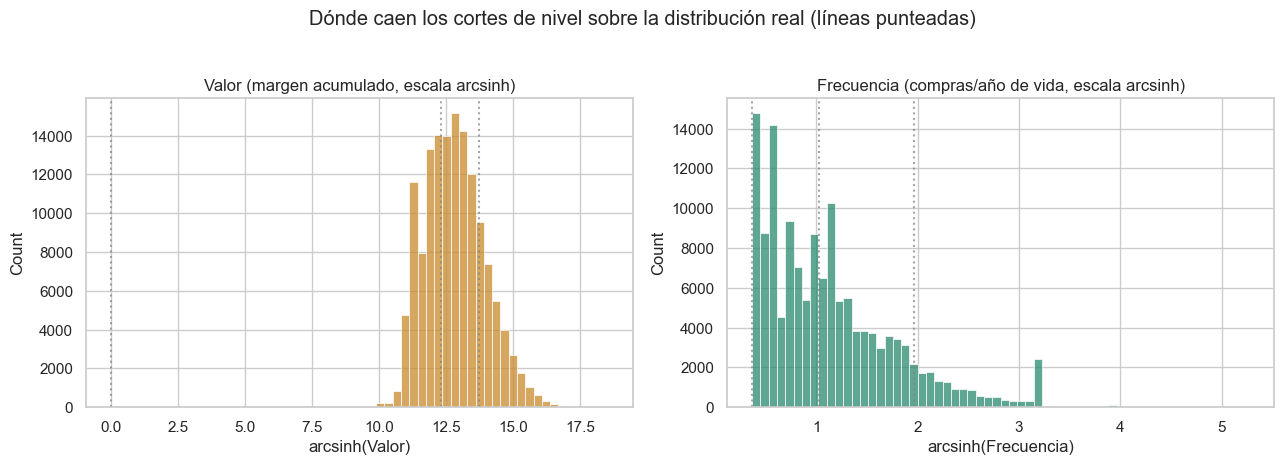

In [233]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(np.arcsinh(clientes["Valor"]), bins=60, ax=axes[0], color="#c98a2b")
for metal in orden_metales:
    corte = np.arcsinh(clientes.loc[clientes["Metal"] == metal, "Valor"].min())
    axes[0].axvline(corte, color="grey", linestyle=":", alpha=0.7)
axes[0].set_title("Valor (margen acumulado, escala arcsinh)")
axes[0].set_xlabel("arcsinh(Valor)")

sns.histplot(np.arcsinh(clientes["Frecuencia"]), bins=60, ax=axes[1], color="#2b8a6f")
for nivel in orden_niveles_frec:
    corte = np.arcsinh(clientes.loc[clientes["NivelFrecuencia"] == nivel, "Frecuencia"].min())
    axes[1].axvline(corte, color="grey", linestyle=":", alpha=0.7)
axes[1].set_title("Frecuencia (compras/año de vida, escala arcsinh)")
axes[1].set_xlabel("arcsinh(Frecuencia)")

fig.suptitle("Dónde caen los cortes de nivel sobre la distribución real (líneas punteadas)", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_3_distribucion_cortes_v2.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Cruce de ejes: los grupos estructurales

**Gráfico 4.** Igual que en la propuesta: no son 27 grupos fijos ni una tabla arbitraria — son el cruce real de los niveles encontrados en cada eje, con la cantidad de clientes y el % del margen total que concentra cada celda.

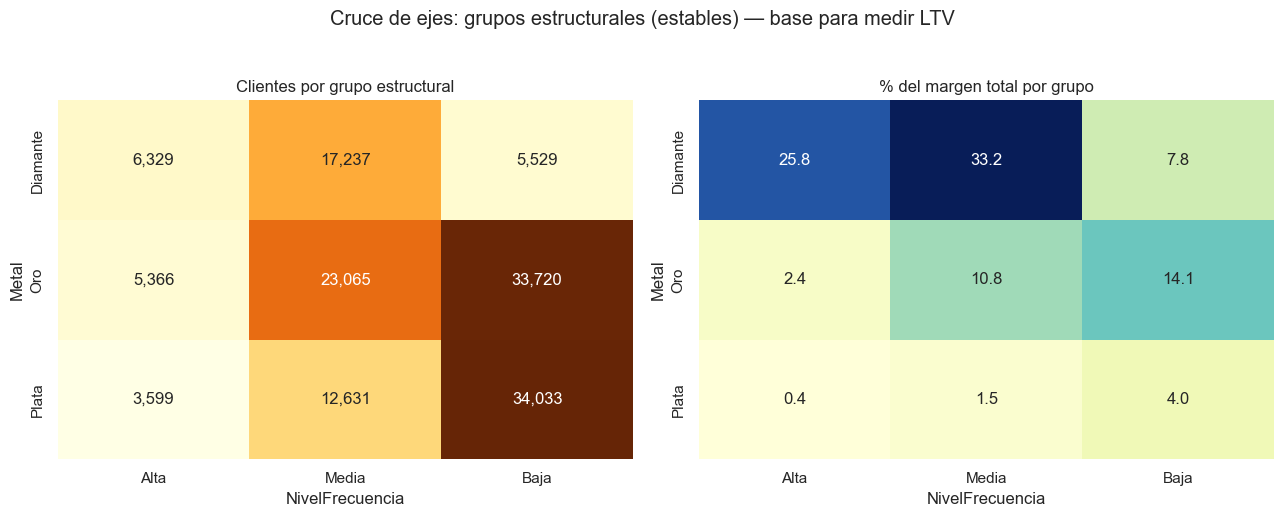

In [234]:
tabla_clientes = clientes.pivot_table(
    index="Metal", columns="NivelFrecuencia", values="ID_Cliente_Unico", aggfunc="count", fill_value=0
).reindex(index=orden_metales, columns=orden_niveles_frec)

tabla_margen_pct = clientes.pivot_table(
    index="Metal", columns="NivelFrecuencia", values="Valor", aggfunc="sum", fill_value=0
).reindex(index=orden_metales, columns=orden_niveles_frec)
tabla_margen_pct = tabla_margen_pct / clientes["Valor"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(tabla_clientes, annot=True, fmt=",", cmap="YlOrBr", ax=axes[0], cbar=False)
axes[0].set_title("Clientes por grupo estructural")

sns.heatmap(tabla_margen_pct, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], cbar=False)
axes[1].set_title("% del margen total por grupo")

fig.suptitle("Cruce de ejes: grupos estructurales (estables) — base para medir LTV", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_4_cruce_grupos_v2.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Umbral de vida por grupo (percentil 90 de intervalos entre compras)

Solo los clientes con 2 o más compras generan intervalos observables. Para cada grupo estructural se junta la distribución de esos intervalos y se toma el percentil 90 — ese es el umbral de "muerte" propio de ese grupo.

In [235]:
fechas_pedido = (
    df_visitas.groupby(["ID_Cliente_Unico", "Pedido"])["Fecha"].min().reset_index()
    .sort_values(["ID_Cliente_Unico", "Fecha"])
)
fechas_pedido["Intervalo_Meses"] = (
    fechas_pedido.groupby("ID_Cliente_Unico")["Fecha"].diff().dt.days / 30.44
)
intervalos = fechas_pedido.dropna(subset=["Intervalo_Meses"])[["ID_Cliente_Unico", "Intervalo_Meses"]]

# Los clientes "Único" (si SEPARAR_UNICO=True) no aportan intervalos aquí de todos
# modos -- al tener una sola compra, su diff() es NaN y el dropna de arriba ya los
# excluye. Su propio umbral (por Metal) se calcula en la celda siguiente.
intervalos = intervalos.merge(
    clientes[["ID_Cliente_Unico", "GrupoEstructural"]],
    on="ID_Cliente_Unico", how="inner",
)

umbral_global = np.percentile(intervalos["Intervalo_Meses"], PERCENTIL_UMBRAL)

umbrales = (
    intervalos.groupby("GrupoEstructural")["Intervalo_Meses"]
    .agg(n_intervalos="count", Umbral_Meses=lambda s: np.percentile(s, PERCENTIL_UMBRAL))
    .reset_index()
)
umbrales["Confiable"] = umbrales["n_intervalos"] >= MIN_INTERVALOS_CONFIABLE
umbrales.loc[~umbrales["Confiable"], "Umbral_Meses"] = umbral_global

print(f"Umbral global (fallback): {umbral_global:.1f} meses")
umbrales.sort_values("Umbral_Meses")

Umbral global (fallback): 11.9 meses


,GrupoEstructural,n_intervalos,Umbral_Meses,Confiable
6,Plata / Alta,252,4.040736,True
3,Oro / Alta,3265,4.829172,True
0,Diamante / Alta,52085,4.862024,True
2,Diamante / Media,57542,11.465177,True
8,Plata / Media,1662,11.626150,True
5,Oro / Media,26403,12.450723,True
7,Plata / Baja,2521,19.612352,True
1,Diamante / Baja,4584,20.696452,True
4,Oro / Baja,12905,20.893561,True


In [236]:
# --- Umbral de "muerte" para los grupos "<Metal> / Único" ---
# Como los clientes "Único" no tienen un segundo intervalo propio, su umbral se deriva
# de la distribución de "días hasta la segunda compra" de los RECOMPRADORES (2+
# compras) de cada Metal (mismo cálculo que antes se hacía de forma global, ahora
# particionado por Metal).
if SEPARAR_UNICO:
    fechas_pedido_metal = (
        df_visitas.groupby(["ID_Cliente_Unico", "Pedido"])["Fecha"].min().reset_index()
        .sort_values(["ID_Cliente_Unico", "Fecha"])
        .merge(clientes[["ID_Cliente_Unico", "Metal"]], on="ID_Cliente_Unico", how="inner")
    )
    cumcount_metal = fechas_pedido_metal.groupby("ID_Cliente_Unico").cumcount()
    dias_hasta_segunda = fechas_pedido_metal.groupby("ID_Cliente_Unico")["Fecha"].diff().dt.days / 30.44
    dias_hasta_segunda = dias_hasta_segunda[cumcount_metal == 1]  # el segundo registro de cada cliente

    umbrales_unico = (
        pd.DataFrame({
            "Metal": fechas_pedido_metal.loc[dias_hasta_segunda.index, "Metal"],
            "Intervalo_Meses": dias_hasta_segunda,
        })
        .groupby("Metal")["Intervalo_Meses"]
        .agg(n_intervalos="count", Umbral_Meses=lambda s: np.percentile(s, PERCENTIL_UMBRAL))
        .reset_index()
    )
    umbrales_unico["Confiable"] = umbrales_unico["n_intervalos"] >= MIN_INTERVALOS_CONFIABLE
    umbrales_unico.loc[~umbrales_unico["Confiable"], "Umbral_Meses"] = umbral_global
    umbrales_unico["GrupoEstructural"] = umbrales_unico["Metal"] + " / Único"
    umbrales_unico = umbrales_unico[["GrupoEstructural", "n_intervalos", "Umbral_Meses", "Confiable"]]

    umbrales = pd.concat([umbrales, umbrales_unico], ignore_index=True)
    print(f"Umbral de 'Único' agregado para {len(umbrales_unico)} metales (basado en recompradores de cada uno).")

umbrales.sort_values("Umbral_Meses")

,GrupoEstructural,n_intervalos,Umbral_Meses,Confiable
6,Plata / Alta,252,4.040736,True
3,Oro / Alta,3265,4.829172,True
0,Diamante / Alta,52085,4.862024,True
2,Diamante / Media,57542,11.465177,True
8,Plata / Media,1662,11.626150,True
5,Oro / Media,26403,12.450723,True
7,Plata / Baja,2521,19.612352,True
1,Diamante / Baja,4584,20.696452,True
4,Oro / Baja,12905,20.893561,True


**Gráfico 5.** Distribución de intervalos entre compras para los 4 grupos con más clientes, con su percentil 90 marcado — el mismo silencio (ej. 5 meses) puede ser normal en un grupo de baja frecuencia y anómalo en uno de alta frecuencia.

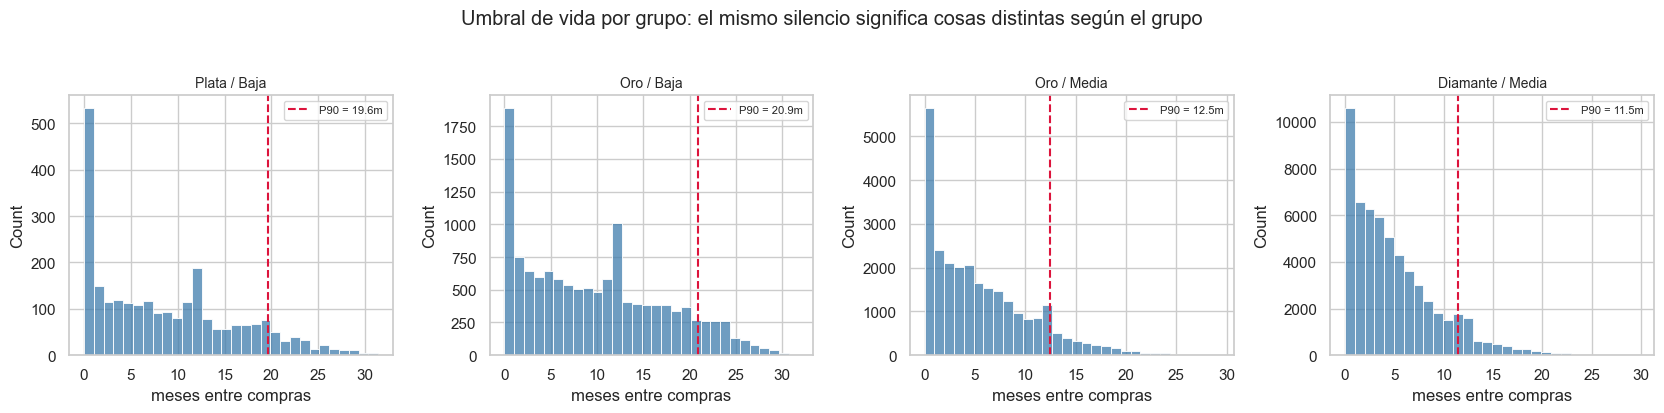

In [237]:
grupos_top = clientes.loc[clientes["NivelFrecuencia"] != "Único", "GrupoEstructural"].value_counts().head(4).index.tolist()
fig, axes = plt.subplots(1, len(grupos_top), figsize=(4.2 * len(grupos_top), 4), sharey=False)
if len(grupos_top) == 1:
    axes = [axes]

for ax, grupo in zip(axes, grupos_top):
    datos = intervalos.loc[intervalos["GrupoEstructural"] == grupo, "Intervalo_Meses"]
    u = umbrales.loc[umbrales["GrupoEstructural"] == grupo, "Umbral_Meses"].iloc[0]
    sns.histplot(datos, bins=30, ax=ax, color="#3f7cac")
    ax.axvline(u, color="crimson", linestyle="--", label=f"P{PERCENTIL_UMBRAL} = {u:.1f}m")
    ax.set_title(grupo, fontsize=10)
    ax.set_xlabel("meses entre compras")
    ax.legend(fontsize=8)

fig.suptitle("Umbral de vida por grupo: el mismo silencio significa cosas distintas según el grupo", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_5_umbrales_por_grupo_v2.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Capa de estado: Activo / Por inactivar / Inactivo

Se compara la recencia de cada cliente contra el umbral de **su propio** grupo estructural.

In [238]:
clientes = clientes.merge(
    umbrales[["GrupoEstructural", "Umbral_Meses", "Confiable"]], on="GrupoEstructural", how="left"
)
clientes["Umbral_Meses"] = clientes["Umbral_Meses"].fillna(umbral_global)


def calcular_estado(row):
    rec, u = row["RecenciaMeses"], row["Umbral_Meses"]
    if rec < CORTE_ACTIVO * u:
        return "Activo"
    elif rec <= u:
        return "Por inactivar"
    else:
        return "Inactivo"


clientes["Estado"] = clientes.apply(calcular_estado, axis=1)
clientes["Estado"].value_counts()

Estado
Activo           61433
Inactivo         44754
Por inactivar    35322
Name: count, dtype: int64

**Gráfico 6.** Reparto de estado en clientes y en margen — la lectura "fotograma" que necesita el CRM, hoy.

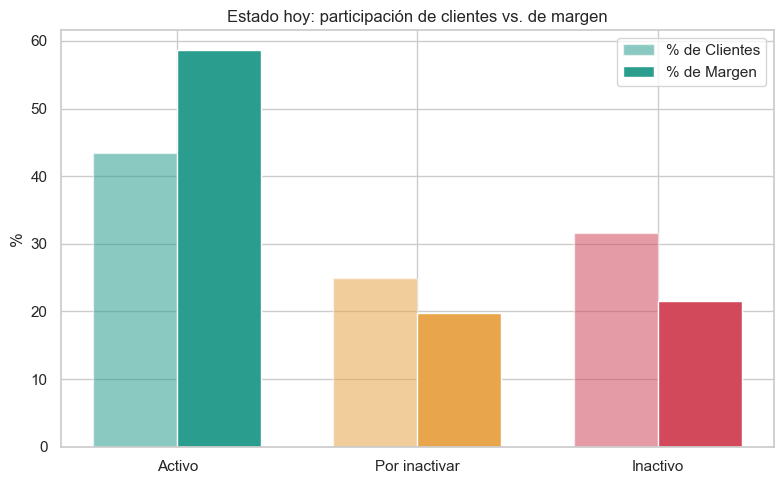

,Clientes,Margen,%Clientes,%Margen
Estado,,,,
Activo,61433,3.106225e+10,43.4,58.6
Por inactivar,35322,1.049756e+10,25.0,19.8
Inactivo,44754,1.143542e+10,31.6,21.6


In [239]:
orden_estado = ["Activo", "Por inactivar", "Inactivo"]
colores_estado = {"Activo": "#2a9d8f", "Por inactivar": "#e9a54c", "Inactivo": "#d1495b"}

resumen_estado = (
    clientes.groupby("Estado")
    .agg(Clientes=("ID_Cliente_Unico", "count"), Margen=("Valor", "sum"))
    .reindex(orden_estado)
)
resumen_estado["%Clientes"] = resumen_estado["Clientes"] / resumen_estado["Clientes"].sum() * 100
resumen_estado["%Margen"] = resumen_estado["Margen"] / resumen_estado["Margen"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(orden_estado))
width = 0.35
ax.bar(x - width / 2, resumen_estado["%Clientes"], width, label="% de Clientes",
       color=[colores_estado[e] for e in orden_estado], alpha=0.55)
ax.bar(x + width / 2, resumen_estado["%Margen"], width, label="% de Margen",
       color=[colores_estado[e] for e in orden_estado])
ax.set_xticks(x)
ax.set_xticklabels(orden_estado)
ax.set_ylabel("%")
ax.set_title("Estado hoy: participación de clientes vs. de margen")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_6_estado_hoy_v2.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_estado.round(1)

## 11. Resumen para el equipo

In [240]:
grupo_top_margen = clientes.groupby("GrupoEstructural")["Valor"].sum().idxmax()
pct_margen_top = clientes.groupby("GrupoEstructural")["Valor"].sum().max() / clientes["Valor"].sum() * 100
pct_clientes_top = (clientes["GrupoEstructural"] == grupo_top_margen).mean() * 100
grupos_no_confiables = umbrales.loc[~umbrales["Confiable"], "GrupoEstructural"].tolist()

ajuste_valor = " (ajustado manualmente)" if K_VALOR != k_valor else ""
ajuste_frec = " (ajustado manualmente)" if K_FRECUENCIA != k_frecuencia else ""

print("RESUMEN PARA EL EQUIPO")
print("=" * 60)
print(f"- Eje de Valor: el codo sugirió {k_valor} niveles; se usaron {K_VALOR}{ajuste_valor} -> {orden_metales}")
print(f"- Eje de Frecuencia: el codo sugirió {k_frecuencia} niveles; se usaron {K_FRECUENCIA}{ajuste_frec} -> {orden_niveles_frec}")
print(f"- Cruce de ejes: {len(orden_metales) * len(orden_niveles_frec)} grupos estructurales posibles")
print(f"- El grupo '{grupo_top_margen}' es el {pct_clientes_top:.1f}% de los clientes")
print(f"  pero concentra el {pct_margen_top:.1f}% del margen total.")
print(f"- Hoy: {resumen_estado.loc['Activo','%Clientes']:.1f}% de los clientes están Activos")
print(f"  ({resumen_estado.loc['Activo','%Margen']:.1f}% del margen), "
      f"{resumen_estado.loc['Inactivo','%Clientes']:.1f}% Inactivos.")
if grupos_no_confiables:
    print(f"- Umbral poco confiable (menos de {MIN_INTERVALOS_CONFIABLE} intervalos observados) en: {grupos_no_confiables}")
    print(f"  Se usó el umbral global ({umbral_global:.1f} meses) como respaldo en esos grupos.")
print("- Gráficos guardados en esta carpeta: grafico_1_v2 a grafico_6_v2 (.png).")

RESUMEN PARA EL EQUIPO
- Eje de Valor: el codo sugirió 2 niveles; se usaron 3 (ajustado manualmente) -> ['Diamante', 'Oro', 'Plata']
- Eje de Frecuencia: el codo sugirió 2 niveles; se usaron 3 (ajustado manualmente) -> ['Alta', 'Media', 'Baja']
- Cruce de ejes: 9 grupos estructurales posibles
- El grupo 'Diamante / Media' es el 12.2% de los clientes
  pero concentra el 33.2% del margen total.
- Hoy: 43.4% de los clientes están Activos
  (58.6% del margen), 31.6% Inactivos.
- Gráficos guardados en esta carpeta: grafico_1_v2 a grafico_6_v2 (.png).


## 12. Resultado final por Cliente

In [241]:
df_master = leer_con_reintentos("""
SELECT Cliente, ID_Cliente_Unico
FROM Ventas_Comerssia.dbo.MASTER_ID
""", engine)

resultado_final = df_master.merge(
    clientes[[
        "ID_Cliente_Unico", "CosechaFecha", "UltimaCompra", "Valor", "Frecuencia",
        "Metal", "NivelFrecuencia", "GrupoEstructural", "RecenciaMeses", "Umbral_Meses", "Estado",
    ]],
    on="ID_Cliente_Unico",
    how="inner",
)

# Filtro de seguridad: un ID_Cliente_Unico puede tener mezclado un Cliente real con uno
# genérico (ej. ID 206829 mezclaba a Catalina Gómez Barrera con "Consumidor Final"); el
# join anterior es por ID_Cliente_Unico, así que aquí se quita explícitamente cualquier
# código de Cliente genérico que se haya colado.
antes = len(resultado_final)
resultado_final = resultado_final[~resultado_final["Cliente"].isin(CLIENTES_EXCLUIR)].reset_index(drop=True)
if antes != len(resultado_final):
    print(f"Filas de Cliente genérico quitadas del resultado final: {antes - len(resultado_final):,}")

print(f"Total filas (clientes): {len(resultado_final):,}")
resultado_final.head(20)

Filas de Cliente genérico quitadas del resultado final: 2
Total filas (clientes): 153,816


,Cliente,ID_Cliente_Unico,CosechaFecha,UltimaCompra,Valor,Frecuencia,Metal,NivelFrecuencia,GrupoEstructural,RecenciaMeses,Umbral_Meses,Estado
0,C1001191851,493874,2026-06-20,2026-06-20,77387.7698,5.072917,Plata,Alta,Plata / Alta,2.365309,4.040736,Activo
1,C1006993270,493875,2026-06-20,2026-06-20,227846.4198,5.072917,Oro,Alta,Oro / Alta,2.365309,4.829172,Activo
2,C1020829429,493880,2026-06-19,2026-06-19,139887.2601,5.003425,Oro,Alta,Oro / Alta,2.398160,4.829172,Activo
3,C1015413107,493882,2026-06-19,2026-06-19,107786.2959,5.003425,Plata,Alta,Plata / Alta,2.398160,4.040736,Activo
4,C1018462550,493883,2026-06-21,2026-06-21,42671.0587,5.144366,Plata,Alta,Plata / Alta,2.332457,4.040736,Activo
5,C1014869550,493885,2026-06-20,2026-06-20,144108.9775,5.072917,Oro,Alta,Oro / Alta,2.365309,4.829172,Activo
6,C1010014340,493887,2026-06-20,2026-07-26,214520.4134,10.145833,Oro,Alta,Oro / Alta,1.182654,4.829172,Activo
7,C1032424152,493888,2026-06-19,2026-06-19,34143.1920,5.003425,Plata,Alta,Plata / Alta,2.398160,4.040736,Activo
8,C1007642609,493889,2026-06-20,2026-06-20,58279.6491,5.072917,Plata,Alta,Plata / Alta,2.365309,4.040736,Activo
9,C1031651885,493890,2026-06-19,2026-06-19,163440.9572,5.003425,Oro,Alta,Oro / Alta,2.398160,4.829172,Activo


## 13. Exportar resultados

In [242]:
with pd.ExcelWriter(OUTPUT_DIR / "segmentacion_valor_frecuencia_v2.xlsx") as writer:
    resultado_final.to_excel(writer, sheet_name="Clientes", index=False)
    umbrales.to_excel(writer, sheet_name="Umbrales_Grupo", index=False)
    resumen_estado.round(1).to_excel(writer, sheet_name="Resumen_Estado")
    clientes_excluidos_margen_negativo.to_excel(writer, sheet_name="Excluidos_Margen_Negativo", index=False)
    tabla_metal_fmt.to_excel(writer, sheet_name="Rango_Valor_Metal")
    tabla_nivel_frecuencia_fmt.to_excel(writer, sheet_name="Rango_Frecuencia_Nivel")

print(f"Exportado: {OUTPUT_DIR / 'segmentacion_valor_frecuencia_v2.xlsx'} (hojas: Clientes, Umbrales_Grupo, Resumen_Estado, Excluidos_Margen_Negativo, Rango_Valor_Metal, Rango_Frecuencia_Nivel)")
print(f"Gráficos exportados como PNG en {OUTPUT_DIR}/ (grafico_1_v2 ... grafico_6_v2)")

# Descomentar para escribir en SQL Server (crea/reemplaza la tabla Segmentacion_ValorFrecuencia)
# resultado_final.to_sql("Segmentacion_ValorFrecuencia", engine, if_exists="replace", index=False)

Exportado: resultados_2024_sin_unico\segmentacion_valor_frecuencia_v2.xlsx (hojas: Clientes, Umbrales_Grupo, Resumen_Estado, Excluidos_Margen_Negativo, Rango_Valor_Metal, Rango_Frecuencia_Nivel)
Gráficos exportados como PNG en resultados_2024_sin_unico/ (grafico_1_v2 ... grafico_6_v2)


## 14. Curva de LTV por cohorte (grupo estructural)

Esta es la pieza que le faltaba a este análisis: la curva de margen acumulado promedio
por mes de vida, para cada grupo estructural. Se apoya en `df_ventas`, `clientes` y
`fecha_corte` que ya están calculados arriba -- no se recalculan Valor, Frecuencia,
Estado ni los umbrales, y no se vuelve a consultar la base de datos.

El punto central de esta construcción es la **censura por madurez** (Paso 3): un
cliente que entró hace 3 meses no puede "opinar" sobre cómo se ve el mes de vida 24,
porque todavía no ha vivido esos 24 meses. Si se le incluyera de todas formas (con su
margen actual, que es todo lo que tiene hasta ahora), el promedio de esa cohorte en
los meses altos quedaría sesgado hacia abajo -- solo porque los clientes recientes
"prestan" un valor bajo a un punto de la curva que en realidad no les corresponde
todavía. Por eso cada cliente solo aporta filas hasta el mes de vida que realmente
ha alcanzado para `fecha_corte`.

In [243]:
# --- Paso 1: Mes de vida por transacción ---
# Copia de trabajo (no se modifica df_ventas original). MesVida = meses completos
# transcurridos entre la cosecha del cliente y cada transacción suya.
ventas_ltv = df_ventas.merge(
    clientes[["ID_Cliente_Unico", "CosechaFecha"]],
    on="ID_Cliente_Unico",
    how="inner",
)
ventas_ltv["MesVida"] = np.floor(
    (ventas_ltv["Fecha"] - ventas_ltv["CosechaFecha"]).dt.days / 30.44
)

filas_negativas = int((ventas_ltv["MesVida"] < 0).sum())
if filas_negativas:
    print(f"Filas excluidas por MesVida negativo (venta registrada antes de la cosecha, error de datos): {filas_negativas:,}")

ventas_ltv = ventas_ltv[ventas_ltv["MesVida"] >= 0].copy()
ventas_ltv["MesVida"] = ventas_ltv["MesVida"].astype(int)
print(f"Filas para la curva de LTV: {len(ventas_ltv):,}")

Filas excluidas por MesVida negativo (venta registrada antes de la cosecha, error de datos): 9
Filas para la curva de LTV: 821,776


### Paso 2 y 3: margen acumulado por cliente y mes de vida, con censura por madurez

Primero se calcula el margen acumulado de cada cliente en los meses de vida donde
tuvo transacciones (Paso 2). Después se construye una grilla explícita: cada cliente
aporta exactamente una fila por cada mes de vida entre 0 y su `MesesVidaActual`
(cuántos meses de vida ha alcanzado ya para `fecha_corte`) -- ni uno más, ni uno
menos. En los meses donde no compró, su margen acumulado se arrastra del último mes
en que sí tuvo movimiento (forward-fill), porque el margen acumulado no baja solo
por no comprar; solo se actualiza cuando hay una transacción nueva.

In [244]:
# --- Paso 2: margen acumulado por cliente en los meses de vida con transacción ---
margen_mes = (
    ventas_ltv.groupby(["ID_Cliente_Unico", "MesVida"])["Margen"].sum()
    .groupby(level=0).cumsum()
    .reset_index(name="MargenAcumulado")
)

# --- Paso 3: censura por madurez ---
# MesesVidaActual = cuántos meses de vida ha alcanzado ya cada cliente para fecha_corte.
clientes_ltv = clientes[["ID_Cliente_Unico", "CosechaFecha", "GrupoEstructural", "Metal", "NivelFrecuencia"]].copy()
clientes_ltv["MesesVidaActual"] = np.floor(
    (fecha_corte - clientes_ltv["CosechaFecha"]).dt.days / 30.44
).astype(int)

# Grilla: cada cliente aporta una fila por cada mes de vida de 0 a MesesVidaActual
# (un cliente con MesesVidaActual=5 aporta exactamente 6 filas, M=0..5).
n_meses = clientes_ltv["MesesVidaActual"].to_numpy() + 1
grid = pd.DataFrame({
    "ID_Cliente_Unico": np.repeat(clientes_ltv["ID_Cliente_Unico"].to_numpy(), n_meses),
    "MesVida": np.concatenate([np.arange(m) for m in n_meses]),
})

curva = grid.merge(margen_mes, on=["ID_Cliente_Unico", "MesVida"], how="left")
curva = curva.merge(
    clientes_ltv[["ID_Cliente_Unico", "GrupoEstructural", "Metal", "NivelFrecuencia"]],
    on="ID_Cliente_Unico", how="left",
)
# Forward-fill dentro de cada cliente: si no compró ese mes, se arrastra el acumulado anterior.
curva = curva.sort_values(["ID_Cliente_Unico", "MesVida"])
curva["MargenAcumulado"] = curva.groupby("ID_Cliente_Unico")["MargenAcumulado"].ffill().fillna(0)

print(f"Filas de la grilla cliente x mes de vida: {len(curva):,}")

Filas de la grilla cliente x mes de vida: 2,705,534


### Paso 4: promedio por grupo, con el denominador correcto

Al promediar el margen acumulado por `GrupoEstructural` y `MesVida`, el denominador
(`n_clientes`) es el número de clientes del grupo que alcanzaron ese mes de vida --
la grilla del paso anterior ya garantiza que un cliente de compra única sigue
apareciendo (con su curva plana, arrastrada) en todos los meses hasta su
`MesesVidaActual`, así que no hace falta ni hay que excluirlo aparte.

In [245]:
# --- Paso 4: promedio por grupo estructural y mes de vida ---
curva_grupo = (
    curva.groupby(["Metal", "NivelFrecuencia", "GrupoEstructural", "MesVida"])
    .agg(
        MargenAcumuladoProm=("MargenAcumulado", "mean"),
        n_clientes=("ID_Cliente_Unico", "count"),
    )
    .reset_index()
    .sort_values(["GrupoEstructural", "MesVida"])
)
curva_grupo.head(10)

,Metal,NivelFrecuencia,GrupoEstructural,MesVida,MargenAcumuladoProm,n_clientes
0,Diamante,Alta,Diamante / Alta,0,3.622052e+05,6329
1,Diamante,Alta,Diamante / Alta,1,4.328232e+05,6182
2,Diamante,Alta,Diamante / Alta,2,5.121478e+05,6021
3,Diamante,Alta,Diamante / Alta,3,5.934275e+05,5863
4,Diamante,Alta,Diamante / Alta,4,6.766544e+05,5694
5,Diamante,Alta,Diamante / Alta,5,7.612634e+05,5572
6,Diamante,Alta,Diamante / Alta,6,8.454052e+05,5431
7,Diamante,Alta,Diamante / Alta,7,9.340410e+05,5292
8,Diamante,Alta,Diamante / Alta,8,1.020537e+06,5216
9,Diamante,Alta,Diamante / Alta,9,1.116769e+06,4975


### Paso 5: tabla y gráfica, cortando donde ya no hay soporte suficiente

Se reutiliza `MIN_INTERVALOS_CONFIABLE` (el mismo umbral de confiabilidad que ya usan
los umbrales de estado) como número mínimo de clientes para confiar en un punto de la
curva. Como `n_clientes` solo puede bajar a medida que aumenta `MesVida` (cada mes
adicional exige haber vivido más), basta con encontrar el último mes de vida por
grupo donde todavía se cumple el mínimo, y cortar ahí -- en vez de dejar que la curva
seguir hasta quedar sostenida por un puñado de clientes.

In [246]:
# --- Paso 5a: cortar cada grupo en el último mes de vida con soporte suficiente ---
MIN_CLIENTES_LTV = MIN_INTERVALOS_CONFIABLE  # mismo umbral de confiabilidad que ya usa el notebook

mes_max_confiable = (
    curva_grupo.loc[curva_grupo["n_clientes"] >= MIN_CLIENTES_LTV]
    .groupby("GrupoEstructural")["MesVida"].max()
    .rename("MesVidaMax")
)
curva_grupo = curva_grupo.merge(mes_max_confiable, on="GrupoEstructural", how="left")
curva_grupo_confiable = curva_grupo[curva_grupo["MesVida"] <= curva_grupo["MesVidaMax"]].drop(columns="MesVidaMax").reset_index(drop=True)

print(f"Meses de vida con soporte >= {MIN_CLIENTES_LTV} clientes, por grupo:")
print(mes_max_confiable.sort_values())

Meses de vida con soporte >= 30 clientes, por grupo:
GrupoEstructural
Plata / Alta         6
Oro / Alta          20
Plata / Media       27
Diamante / Baja     31
Diamante / Media    31
Oro / Baja          31
Oro / Media         31
Diamante / Alta     31
Plata / Baja        31
Name: MesVidaMax, dtype: int64


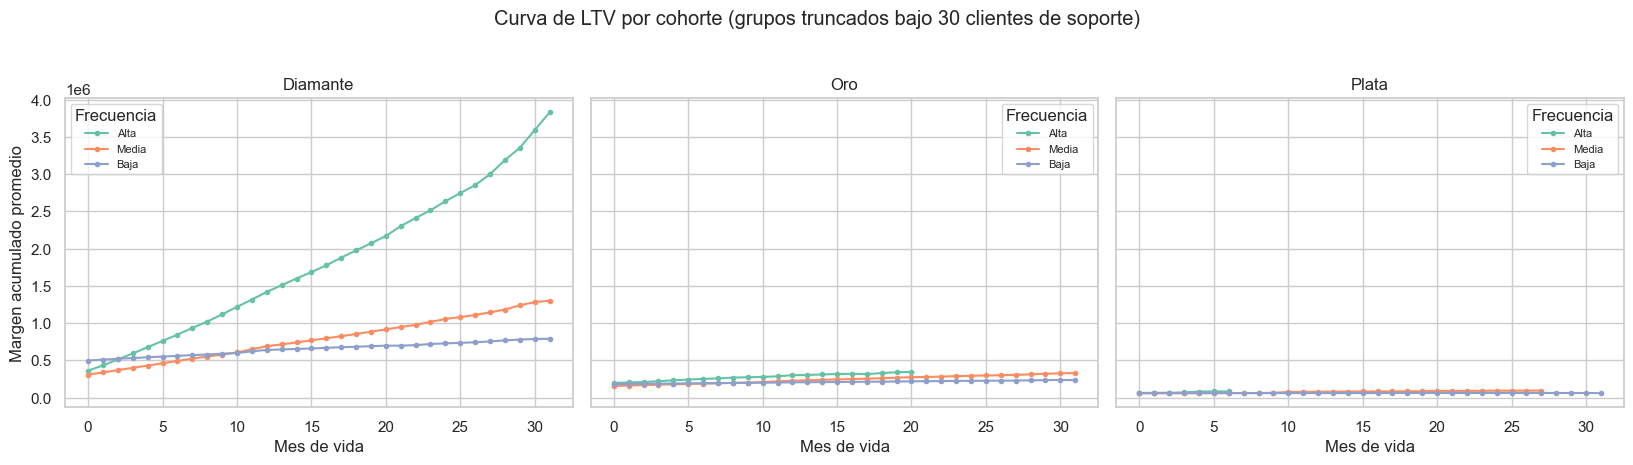

In [247]:
# --- Paso 5b: gráfica -- una figura por Metal, una línea por NivelFrecuencia ---
colores_nivel = dict(zip(orden_niveles_frec, sns.color_palette("Set2", len(orden_niveles_frec))))
metales_con_datos = [m for m in orden_metales if m in curva_grupo_confiable["Metal"].unique()]

fig, axes = plt.subplots(1, len(metales_con_datos), figsize=(5.5 * len(metales_con_datos), 4.5), sharey=True)
if len(metales_con_datos) == 1:
    axes = [axes]

for ax, metal in zip(axes, metales_con_datos):
    datos_metal = curva_grupo_confiable[curva_grupo_confiable["Metal"] == metal]
    for nivel in orden_niveles_frec:
        datos_linea = datos_metal[datos_metal["NivelFrecuencia"] == nivel].sort_values("MesVida")
        if datos_linea.empty:
            continue
        ax.plot(
            datos_linea["MesVida"], datos_linea["MargenAcumuladoProm"],
            marker="o", markersize=3, color=colores_nivel[nivel], label=nivel,
        )
    ax.set_title(metal)
    ax.set_xlabel("Mes de vida")
    ax.legend(title="Frecuencia", fontsize=8)

axes[0].set_ylabel("Margen acumulado promedio")
fig.suptitle(f"Curva de LTV por cohorte (grupos truncados bajo {MIN_CLIENTES_LTV} clientes de soporte)", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "grafico_7_curva_ltv_v2.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Exportar la curva de LTV

Se agrega como una hoja nueva (`Curva_LTV`) al mismo Excel que ya exporta el resto
del notebook -- no se vuelve a escribir sobre las hojas `Clientes`, `Umbrales_Grupo`
ni `Resumen_Estado`.

In [248]:
# --- Paso 6: exportar ---
with pd.ExcelWriter(OUTPUT_DIR / "segmentacion_valor_frecuencia_v2.xlsx", mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    curva_grupo_confiable.to_excel(writer, sheet_name="Curva_LTV", index=False)

print(f"Hoja 'Curva_LTV' agregada a {OUTPUT_DIR / 'segmentacion_valor_frecuencia_v2.xlsx'}")
print(f"Gráfico guardado: {OUTPUT_DIR / 'grafico_7_curva_ltv_v2.png'}")

Hoja 'Curva_LTV' agregada a resultados_2024_sin_unico\segmentacion_valor_frecuencia_v2.xlsx
Gráfico guardado: resultados_2024_sin_unico\grafico_7_curva_ltv_v2.png
